In [1]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [2]:
# Параметры симуляции для MEEP
resolution = 50  # разрешение сетки (точек на длину волны)
wavelength = 3.7  # длина волны источника
X_cell_size = conf.cell_X + 2
Y_cell_size = 75*2
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.ALL, side=mp.ALL)]
#symmetries = [mp.Mirror(mp.Y)]

sources = [mp.Source(
    mp.GaussianSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=mp.Vector3(x=-X_cell_size/2 +conf.in_pml),
    size=mp.Vector3(x=0, y=Y_cell_size),
)]

In [3]:
# Все параметры касающиеся определения геометрии
M = 14 # число радиальных слоёв.
k = 2 * np.pi / wavelength # волновое число
f = 50 # focal length 500 microns
ff_res = 20 # far field resolution (points/μm)
spot_length = 50  # far field line length
Q = 300 # детализация
w = 1 # 1000 nm (расстояние промежутка)
epsilon = 0.02  # Задайте точность, с которой y1 должен быть равен w

centers = []
width_curves = []
geometry = []
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, conf.cell_Z),
    center=mp.Vector3(conf.sub_center[0] - 1),
))

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)


# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))
def zero_derivative (n):
    calculation = np.sqrt((4 * f * n * np.pi)/k)
    return calculation

# Main loop for layers
for m in range(M):
    center = zero_derivative(m)
    centers.append(center)
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m] - 0.01, Q)
    # Compute y values by integration
    y = np.array([quad(fun, rt0, xi)[0] for xi in x])
    xt = x.copy()
    ip = np.argmin(y)
    y1 = y - y[ip]

    # Найти первое значение x, при котором y1 примерно равно w
    index = np.argmax(np.abs(y1 - w) < epsilon)
    if np.abs(y1[index] - w) < epsilon:
        x_first_close_to_w = x[index]
    else:
        raise ValueError(f"Для слоя {m} значение x, соответствующее y1 ≈ {w}, не найдено. Увеличь Q!")

    dx = abs(2*(center - x[index]))
    width_curves.append(dx)

    print(f'Параметры ячейки для порядка {m}: width = {dx:.2f} | center = {center:.2f}')

Параметры ячейки для порядка 0: width = 14.00 | center = 0.00
Параметры ячейки для порядка 1: width = 4.81 | center = 19.24
Параметры ячейки для порядка 2: width = 3.93 | center = 27.20
Параметры ячейки для порядка 3: width = 3.45 | center = 33.32
Параметры ячейки для порядка 4: width = 3.16 | center = 38.47
Параметры ячейки для порядка 5: width = 2.95 | center = 43.01
Параметры ячейки для порядка 6: width = 2.79 | center = 47.12
Параметры ячейки для порядка 7: width = 2.65 | center = 50.89
Параметры ячейки для порядка 8: width = 2.53 | center = 54.41
Параметры ячейки для порядка 9: width = 2.43 | center = 57.71
Параметры ячейки для порядка 10: width = 2.35 | center = 60.83
Параметры ячейки для порядка 11: width = 2.29 | center = 63.80
Параметры ячейки для порядка 12: width = 2.21 | center = 66.63
Параметры ячейки для порядка 13: width = 2.15 | center = 69.35


In [4]:
# Зальем теперь это все в геометрию
for m in range(M):
    geometry.append(mp.Block(
        material=conf.at_material,
        size=mp.Vector3(conf.at_hei, width_curves[m], 0),
        center=mp.Vector3(x=-X_cell_size/2+conf.in_pml + conf.at_hei/2 + conf.in_gap + conf.in_sub/2, y=centers[m], z=0)
    ))
    
    geometry.append(mp.Block(
        material=conf.at_material,
        size=mp.Vector3(conf.at_hei, width_curves[m], 0),
        center=mp.Vector3(x=-X_cell_size/2+conf.in_pml + conf.at_hei/2 + conf.in_gap + conf.in_sub/2, y=-centers[m], z=0)
    ))

In [5]:
geometry[0].center

Vector3<-1.5, 0.0, 0.0>

In [6]:
len(geometry)

29

In [7]:
cell

Vector3<11.0, 150.0, 0.0>

     block, center = (-1.5,0,0)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,0,0)
          size (1,14.0006,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,-0,0)
          size (1,14.0006,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,19.2354,0)
          size (1,4.81056,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,-19.2354,0)
          size (1,4.81056,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,27.2029,0)
          size (1,3.93064,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = 

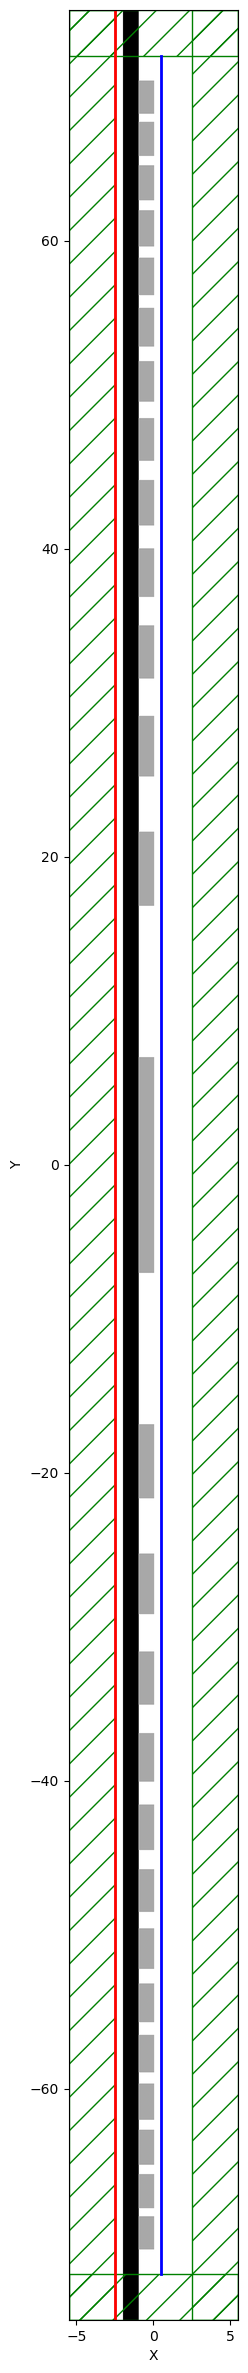

In [8]:
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=resolution,
    #symmetries = symmetries,
)

n2f_obj = sim.add_near2far(
    conf.inc_fcen, 0, 1, mp.Near2FarRegion(center=mp.Vector3(x=-X_cell_size/2+conf.in_pml + conf.at_hei + conf.in_gap + 1), size=mp.Vector3(y=cell[1] - conf.in_pml*2))
)

plt.figure(figsize=(8, 30))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0], cell[1],0)) 
)

plt.savefig("simulation_plot.png", dpi = 100)  # Сохранение изображения в файл
plt.show()  # Отображение изображения


In [9]:
sim.run(until_after_sources=100)
result = abs(
            sim.get_farfields(
                n2f_obj,
                ff_res,
                center=mp.Vector3(x=-X_cell_size/2+conf.in_pml + conf.at_hei + conf.in_gap + f),
                size=mp.Vector3(spot_length),
            )["Ez"]
) ** 2

-----------
Initializing structure...
time for choose_chunkdivision = 0.00209904 s
Working in 2D dimensions.
Computational cell is 11 x 150 x 0 with resolution 50
     block, center = (-1.5,0,0)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,0,0)
          size (1,14.0006,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,-0,0)
          size (1,14.0006,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,19.2354,0)
          size (1,4.81056,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6,4.6)
     block, center = (-0.5,-19.2354,0)
          size (1,4.81056,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (4.6,4.6

FloatProgress(value=0.0, description='0% done ', max=470.0)

Meep progress: 1.72/470.0 = 0.4% done in 4.0s, 1094.5s to go
on time step 172 (time=1.72), 0.0233592 s/step
Meep progress: 3.5700000000000003/470.0 = 0.8% done in 8.0s, 1050.4s to go
on time step 357 (time=3.57), 0.0217258 s/step
Meep progress: 5.42/470.0 = 1.2% done in 12.0s, 1032.3s to go
on time step 542 (time=5.42), 0.0216358 s/step
Meep progress: 6.44/470.0 = 1.4% done in 16.7s, 1204.4s to go
on time step 644 (time=6.44), 0.0459649 s/step
Meep progress: 8.23/470.0 = 1.8% done in 20.7s, 1163.7s to go
on time step 823 (time=8.23), 0.0223951 s/step
Meep progress: 9.97/470.0 = 2.1% done in 24.8s, 1142.1s to go
on time step 997 (time=9.97), 0.0230424 s/step
Meep progress: 11.83/470.0 = 2.5% done in 28.8s, 1113.5s to go
on time step 1184 (time=11.84), 0.0215002 s/step
Meep progress: 13.68/470.0 = 2.9% done in 32.8s, 1092.8s to go
on time step 1369 (time=13.69), 0.0216851 s/step
Meep progress: 15.280000000000001/470.0 = 3.3% done in 36.8s, 1094.1s to go
on time step 1529 (time=15.29), 0.

KeyboardInterrupt: 

In [ ]:
x = np.linspace(
    -0.5 * spot_length,
    + 0.5 * spot_length,
    ff_res * spot_length,
)

plt.figure(dpi=100)
plt.semilogy(
    x, ff_nc, label="Far field"
)
plt.xlabel("x coordinate (μm)")
plt.ylabel(r"energy density of far-field electric fields, |E$_z$|$^2$")
plt.title("focusing properties of CC metasurface lens")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()